# Text Classification과 Sentiment Analysis

**본인 사본을 만들어 실행·수정·기록하세요.**

- 이름: **이윤호**
- 학번: **2022204025**

[자습 자료](https://nii-lab.github.io/ko/courses/ai-applications/text-classification/index.html)

<!-- exercise-guidance:ai-applications/text-classification/execution -->
- Code Cell 실행: ▶ 또는 `Shift+Enter`, 위에서부터 순서대로.
- Text Cell 작성: 더블클릭 → `직접 입력` 작성 → `Shift+Enter`.
- 직접 작성 셀: 본인 코드 입력.
- 값 변경 후: 해당 셀과 뒤의 관련 셀 다시 실행.
<!-- /exercise-guidance:ai-applications/text-classification/execution -->


## 1. 토큰과 vocabulary

문장을 Token과 Index로 바꾸고, Embedding 벡터를 평균 내어 문장 전체의 감정을 분류합니다. 이번 실습은 전처리 결과와 문장 벡터를 직접 확인하기 위해 짧은 영어 Review와 학습 가능한 Mean Embedding 모델을 사용합니다. 강의의 IMDB 예제처럼 문장 전체에 Label을 붙이되, 여기서는 세 감정으로 분류합니다. Mean Pooling은 단어 순서를 생략한 단순한 모델이며 RNN을 반드시 대체해야 해서 사용하는 것은 아닙니다. TorchText 설치, Hugging Face 로그인, 외부 모델 다운로드는 필요하지 않습니다. PAD=0은 빈자리, UNK=1은 모르는 단어입니다. screen size okay처럼 짧은 문장에 PAD가 붙는지 확인하고, 아래 비교 셀에서도 다른 길이의 문장을 사용합니다.

### A. 기준 예제 · 먼저 읽고 실행

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
torch.manual_seed(42)
torch.set_num_threads(2)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
texts=['great battery bright screen','bad camera slow app','screen size okay','love fast performance','broken charger bad battery','average design normal speed','great sound love display','slow response hate keyboard','okay price average camera','bright screen fast app','bad screen okay battery','normal package average manual']
y=torch.tensor([2,0,1,2,0,1,2,0,1,2,0,1]);names=['negative','neutral','positive']
words=sorted(set(' '.join(texts).split()));vocab={'<PAD>':0,'<UNK>':1,**{w:i+2 for i,w in enumerate(words)}}
def encode(text_list):
    rows=[[vocab.get(w,1) for w in text.lower().split()] or [1] for text in text_list]
    length=max(map(len,rows));return torch.tensor([r+[0]*(length-len(r)) for r in rows])
X=encode(texts);print(texts[:3],X[:3],X.shape)


# 길이가 다를 때 PAD가 들어가는 위치를 확인합니다.
probe_texts = ['great battery', 'great battery bright screen', 'excellent battery']
probe_ids = encode(probe_texts)
for text, row in zip(probe_texts, probe_ids):
    print('text:', text, '| tokens:', text.lower().split(), '| ids:', row.tolist())
assert (probe_ids[0] == 0).sum().item() == 2
assert probe_ids[2, 0].item() == vocab['<UNK>']


Python: 3.12.3 | PyTorch: 2.12.0+cu130
['great battery bright screen', 'bad camera slow app', 'screen size okay'] tensor([[13,  5,  6, 24],
        [ 4,  8, 26,  2],
        [24, 25, 19,  0]]) torch.Size([12, 4])
text: great battery | tokens: ['great', 'battery'] | ids: [13, 5, 0, 0]
text: great battery bright screen | tokens: ['great', 'battery', 'bright', 'screen'] | ids: [13, 5, 6, 24]
text: excellent battery | tokens: ['excellent', 'battery'] | ids: [1, 5, 0, 0]


### B. 직접 수행

<!-- exercise-guidance:ai-applications/text-classification/activity-1 -->
1. 길이가 다른 두 영어 문장을 Token → Index → PAD 순서로 출력하세요.
2. 학습 사전에 없는 단어 하나를 넣고 UNK 위치를 확인하세요.
3. 실제 단어를 뜻하는 Index와 PAD·UNK를 구별해 적으세요.
<!-- /exercise-guidance:ai-applications/text-classification/activity-1 -->

예상은 정확한 수치 대신 shape나 증가·감소 방향으로 적어도 됩니다. 설명은 아래 Text Cell에 기록하세요.


In [ ]:
activity1_texts = [
    'great battery',
    'great battery bright screen',
    'excellent battery'
]
activity1_ids = encode(activity1_texts)

for text, row in zip(activity1_texts, activity1_ids):
    tokens = text.lower().split()
    print('문장:', text)
    print('Token:', tokens)
    print('Index + PAD:', row.tolist())

print('PAD index:', vocab['<PAD>'], '| UNK index:', vocab['<UNK>'])
print('일반 단어 Index는 2 이상입니다.')
assert activity1_ids.shape == (3, 4)
assert (activity1_ids[0] == vocab['<PAD>']).sum().item() == 2
assert activity1_ids[2, 0].item() == vocab['<UNK>']

문장: great battery
Token: ['great', 'battery']
Index + PAD: [13, 5, 0, 0]
문장: great battery bright screen
Token: ['great', 'battery', 'bright', 'screen']
Index + PAD: [13, 5, 6, 24]
문장: excellent battery
Token: ['excellent', 'battery']
Index + PAD: [1, 5, 0, 0]
PAD index: 0 | UNK index: 1
일반 단어 Index는 2 이상입니다.


### C. 직접 기록 · 이 Text Cell을 더블클릭해서 수정

- 확인하거나 바꾼 조건: 길이가 다른 `great battery`, `great battery bright screen`과 사전에 없는 `excellent`를 입력했습니다.
- 실행 전 예상: 두 번째 문장 길이에 맞춰 첫 문장 뒤에 PAD가 붙고, `excellent`는 UNK index 1이 될 것입니다.
- 실제 출력/그래프에서 확인한 값: shape는 (3, 4), `great battery`는 `[13, 5, 0, 0]`, 긴 문장은 `[13, 5, 6, 24]`, `excellent battery`는 `[1, 5, 0, 0]`으로 출력되었습니다.
- 예상과 차이 및 설명: 일반 단어 index는 2 이상이고 PAD는 0, UNK는 1이라 서로 구분됩니다.

## 2. 마스킹한 평균과 학습

12·13주차는 문자마다 다음 문자를 예측했지만 이번에는 문장당 감정 하나를 예측합니다. Embedding (N,S,16)에서 PAD를 뺀 평균 (N,16)을 만든 뒤 Linear로 (N,3) Logit을 만듭니다. Embedding과 Linear는 함께 학습되며, 이 모델에는 RNN/LSTM이 없습니다.

### A. 기준 예제 · 먼저 읽고 실행

Training accuracy: 1.0
embedding: torch.Size([12, 4, 16])


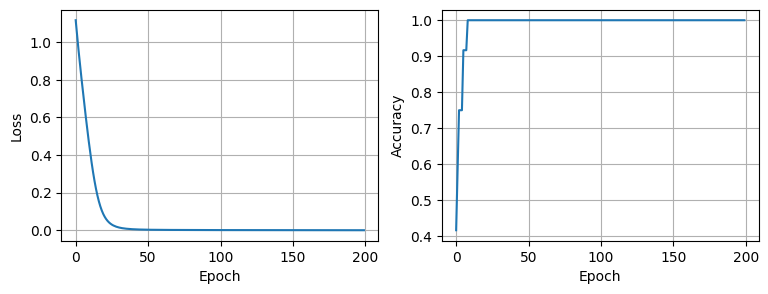

PAD 포함 평균과 차이: 1.0996325016021729
PAD 제외 평균과 차이: 0.0
단어 순서를 바꾼 두 문장의 Logit: tensor([[ 0.4835, -1.7217,  4.3325],
        [ 0.4835, -1.7217,  4.3325]])


In [3]:
class TextClassifier(nn.Module):
    def __init__(self):
        super().__init__();self.embedding=nn.Embedding(len(vocab),16,padding_idx=0);self.fc=nn.Linear(16,3)
    def forward(self,ids):
        mask=(ids!=0).unsqueeze(-1);embedded=self.embedding(ids)
        pooled=(embedded*mask).sum(1)/mask.sum(1).clamp_min(1)
        return self.fc(pooled)
model=TextClassifier();opt=torch.optim.Adam(model.parameters(),lr=.02);losses=[];accuracies=[]
for epoch in range(200):
    logits=model(X);loss=F.cross_entropy(logits,y)
    opt.zero_grad();loss.backward();opt.step()
    losses.append(loss.item());accuracies.append((logits.argmax(1)==y).float().mean().item())
print('Training accuracy:',accuracies[-1]);print('embedding:',model.embedding(X).shape)
fig,axes=plt.subplots(1,2,figsize=(9,3));axes[0].plot(losses);axes[1].plot(accuracies)
for ax,yl in zip(axes,['Loss','Accuracy']):ax.set(xlabel='Epoch',ylabel=yl);ax.grid()
plt.show()


# 같은 문장을 혼자 처리하거나 긴 문장과 묶어도, 올바른 평균은 같습니다.
with torch.no_grad():
    single_ids = encode(['great battery'])
    batch_ids = encode(['great battery', 'great battery bright screen'])
    single_vector = model.embedding(single_ids).mean(1)[0]
    batch_embedded = model.embedding(batch_ids)
    mask = (batch_ids != 0).unsqueeze(-1)
    masked_vectors = (batch_embedded * mask).sum(1) / mask.sum(1).clamp_min(1)
    plain_vectors = batch_embedded.mean(1)
    print('PAD 포함 평균과 차이:', (single_vector - plain_vectors[0]).abs().max().item())
    print('PAD 제외 평균과 차이:', (single_vector - masked_vectors[0]).abs().max().item())
    assert torch.allclose(single_vector, masked_vectors[0], atol=1e-6)
    order_logits = model(encode(['great battery', 'battery great']))
    print('단어 순서를 바꾼 두 문장의 Logit:', order_logits)
    assert torch.allclose(order_logits[0], order_logits[1], atol=1e-6)


### B. 직접 수행

<!-- exercise-guidance:ai-applications/text-classification/activity-2 -->
1. 제공된 두 문장의 평균 비교 셀을 실행하세요. 짧은 문장을 단독 처리한 Vector를 기준으로, 긴 문장과 함께 처리한 Vector의 최대 절대 차이를 Mask 적용 전·후 각각 기록하세요.
2. 비교 셀에서 `single_ids`의 문장과 `batch_ids`의 첫 문장을 같은 짧은 문장으로 함께 바꾸세요. `batch_ids`의 둘째 문장은 그보다 긴 문장으로 바꾸고 같은 계산을 반복하세요. 사용한 문장과 두 차이를 기록하세요. 학습한 Embedding 가중치는 유지합니다.
3. 단어 순서를 바꾼 두 문장의 Logit을 나란히 적고 최대 절대 차이를 구하세요. 현재 문장의 Token 수·PAD 수와 출력된 최대 차이를 근거로, PAD 포함 여부가 평균에 미친 영향과 평균 Pooling에서 단어 순서가 바뀐 영향을 나누어 설명하세요.
<!-- /exercise-guidance:ai-applications/text-classification/activity-2 -->

예상은 정확한 수치 대신 shape나 증가·감소 방향으로 적어도 됩니다. 설명은 아래 Text Cell에 기록하세요.


In [ ]:
activity2_short = 'great battery'
activity2_long = 'great battery bright screen fast'
activity2_ids = encode([activity2_short, activity2_long])
activity2_single_ids = encode([activity2_short])

with torch.no_grad():
    activity2_single = model.embedding(activity2_single_ids).mean(1)[0]
    activity2_embedded = model.embedding(activity2_ids)
    activity2_mask = (activity2_ids != vocab['<PAD>']).unsqueeze(-1)
    activity2_masked = (activity2_embedded * activity2_mask).sum(1) / activity2_mask.sum(1).clamp_min(1)
    activity2_unmasked = activity2_embedded.mean(1)
    activity2_unmasked_diff = (activity2_single - activity2_unmasked[0]).abs().max().item()
    activity2_masked_diff = (activity2_single - activity2_masked[0]).abs().max().item()

    activity2_order_ids = encode(['great battery', 'battery great'])
    activity2_order_logits = model(activity2_order_ids)
    activity2_order_diff = (activity2_order_logits[0] - activity2_order_logits[1]).abs().max().item()

print('문장:', activity2_short, '| 긴 문장:', activity2_long)
print('Batch shape:', tuple(activity2_ids.shape), '| 짧은 문장 PAD 수:', int((activity2_ids[0] == 0).sum()))
print('PAD 포함 평균 최대 절대 차이:', activity2_unmasked_diff)
print('PAD 제외 평균 최대 절대 차이:', activity2_masked_diff)
print('순서 변경 Logit:', activity2_order_logits)
print('순서 변경 최대 절대 차이:', activity2_order_diff)
assert activity2_ids.shape == (2, 5)
assert int((activity2_ids[0] == 0).sum()) == 3
assert activity2_unmasked_diff > 0
assert activity2_masked_diff < 1e-6
assert activity2_order_diff < 1e-6

문장: great battery | 긴 문장: great battery bright screen fast
Batch shape: (2, 5) | 짧은 문장 PAD 수: 3
PAD 포함 평균 최대 절대 차이: 1.3195589780807495
PAD 제외 평균 최대 절대 차이: 0.0
순서 변경 Logit: tensor([[ 0.4835, -1.7217,  4.3325],
        [ 0.4835, -1.7217,  4.3325]])
순서 변경 최대 절대 차이: 0.0


### C. 직접 기록 · 이 Text Cell을 더블클릭해서 수정

- 확인하거나 바꾼 조건: `great battery`를 단독 처리하고, `great battery bright screen fast`와 묶어 처리하였습니다. 순서 비교에는 `great battery`와 `battery great`를 사용했습니다.
- 실행 전 예상: Batch shape는 (2, 5)이고 짧은 문장에 PAD 3개가 생기고 PAD 포함 평균은 달라지지만 마스킹 평균과 순서 변경 Logit은 같을 것
- 실제 출력/그래프에서 확인한 값: 기준 비교는 PAD 포함 1.0996, 제외 0.0 차이였습니다. 변경 문장 Batch shape는 (2, 5), PAD 3개이며 차이는 포함 1.3196, 제외 0.0입니다.
- 예상과 차이 및 설명: PAD를 0으로 채워도 일반 평균의 분모에는 PAD가 포함되어 벡터 크기가 달라집니다.

## 3. 새 문장 직접 입력

아래 my_reviews의 빈 문자열 세 개를 영어 문장으로 바꾸세요. 처음에는 texts에 나온 단어를 사용하고, 다음에는 모르는 단어 하나를 추가합니다. 의도한 감정과 모델 예측이 다르더라도 결과와 이유를 기록하세요. 미작성 상태에서는 예측을 건너뜁니다.

### A. 기준 예제 · 먼저 읽고 실행

In [5]:
my_reviews=['great sound love display','average design normal speed','bad camera slow app'] # 긍정, 중립, 부정 예문
if all(s.strip() for s in my_reviews):
    model.eval()
    with torch.no_grad():prob=model(encode(my_reviews)).softmax(1)
    for text,p in zip(my_reviews,prob):print(text,'=>',names[p.argmax().item()],p.tolist())
else:
    print('my_reviews의 빈 문자열 3개를 직접 작성하고 이 셀을 다시 실행하세요.')
print('unknown token example:',encode(['excellent battery']))



great sound love display => positive [8.58296152728144e-06, 9.069871885003522e-05, 0.9999006986618042]
average design normal speed => neutral [9.339049029222224e-06, 0.9999068975448608, 8.376545156352222e-05]
bad camera slow app => negative [0.9995779395103455, 0.00028041581390425563, 0.00014162143634166569]
unknown token example: tensor([[1, 5]])


### B. 직접 수행

<!-- exercise-guidance:ai-applications/text-classification/activity-3 -->
1. 학습 사전의 단어로 긍정·중립·부정 영어 문장을 하나씩 my_reviews에 작성하세요.
2. 의도한 감정·예측·Token을 기록하고, 모르는 단어나 문장부호를 하나 넣어 UNK 처리를 확인하세요.
3. 예측이 의도와 달라도 원인을 설명하면 됩니다.
<!-- /exercise-guidance:ai-applications/text-classification/activity-3 -->

예상은 정확한 수치 대신 shape나 증가·감소 방향으로 적어도 됩니다. 설명은 아래 Text Cell에 기록하세요.


In [ ]:
unknown_review = 'excellent battery'
unknown_tokens = unknown_review.lower().split()
unknown_ids = encode([unknown_review])
with torch.no_grad():
    unknown_prob = model(unknown_ids).softmax(1)[0]
print('문장:', unknown_review)
print('Token:', unknown_tokens, '| Index:', unknown_ids[0].tolist())
print('예측:', names[unknown_prob.argmax().item()], '| 확률:', unknown_prob.tolist())
assert unknown_ids[0, 0].item() == vocab['<UNK>']
assert unknown_tokens[0] not in vocab

문장: excellent battery
Token: ['excellent', 'battery'] | Index: [1, 5]
예측: negative | 확률: [0.9978227615356445, 0.0013764641480520368, 0.0008008002769201994]


### C. 직접 기록 · 이 Text Cell을 더블클릭해서 수정

- 확인하거나 바꾼 조건: 학습 사전에 있는 단어만 쓴 긍정·중립·부정 리뷰와 사전에 없는 `excellent`를 비교했습니다.
- 실행 전 예상: 입력 리뷰는 예측 결과가 출력되고, `excellent`는 UNK index 1로 인코딩될 것입니다.
- 실제 출력/그래프에서 확인한 값: 익숙한 단어 문장은 positive·neutral·negative로, `excellent battery`는 Token `['excellent', 'battery']`, Index `[1, 5]`로 바뀌고 negative로 관측됨
- 예상과 차이 및 설명: `excellent`는 학습에 없으므로 UNK의 학습된 의미가 없습니다.

## 반복 숙달 · 실행 전에 판단하기

앞의 직접 수행에서 비교한 조건 세 가지를 이 표에 정리하세요. 이미 수행한 실험을 다시 추가할 필요는 없습니다. 비교가 부족하면 한 조건만 바꾸어 보충하세요.

| 변경 조건 | 예상 shape/수치/결과 | 실제 결과 | 오류가 있었다면 원인 |
|---|---|---|---|
| 짧은 문장과 긴 문장을 함께 Batch 처리 | shape (2, 5), 짧은 문장 뒤 PAD 3개 | 실제 shape (2, 5), PAD 3개 | - |
| 평균에서 PAD 마스킹 | 마스킹 전 차이 > 0, 마스킹 후 차이 ≈ 0 | 최대 차이 1.3196 → 0.0 | PAD를 평균 분모에서 제외해야 함 |
| 두 단어의 순서 변경 | 평균 Pooling 결과와 Logit 차이 ≈ 0 | 두 Logit 동일, 최대 차이 0.0 | 평균 Pooling은 순서 정보를 버림 |

In [ ]:
print('1) Batch shape / 짧은 문장 PAD 수:', tuple(activity2_ids.shape), int((activity2_ids[0] == 0).sum()))
print('2) PAD 포함 / 제외 최대 차이:', activity2_unmasked_diff, activity2_masked_diff)
print('3) 단어 순서 변경 최대 Logit 차이:', activity2_order_diff)
print('4) UNK 예문 Token / Index:', unknown_tokens, unknown_ids[0].tolist())

1) Batch shape / 짧은 문장 PAD 수: (2, 5) 3
2) PAD 포함 / 제외 최대 차이: 1.3195589780807495 0.0
3) 단어 순서 변경 최대 Logit 차이: 0.0
4) UNK 예문 Token / Index: ['excellent', 'battery'] [1, 5]


## 선택 실습 · 오류의 원인을 찾아 코드 고치기

<!-- exercise-guidance:ai-applications/text-classification/optional -->
**Embedding에 Float Tensor의 Token Index를 전달한 경우**

1. 문장 분류 모델 학습까지 마친 뒤, 노트북 맨 아래에 Code Cell을 추가하고 다음 코드를 실행하세요.
   
   ```python
   for debug_input in [X.float(), X]:
       print("Token Index:", debug_input.shape, debug_input.dtype)
       try:
           with torch.no_grad():
               print("Output:", model(debug_input).shape)
       except (RuntimeError, ValueError) as error:
           print(type(error).__name__, str(error))
   ```
2. Text Cell에 각 입력의 dtype과 실행 성공 여부를 표로 적으세요. Embedding 입력이 단어의 연속적인 측정값이 아니라 Vocabulary의 행 번호라는 점과 오류 원인을 연결해 설명하세요. `X.float()` 호출 후에도 원래 `X`는 정수형입니다.
<!-- /exercise-guidance:ai-applications/text-classification/optional -->

## 저장 전 확인

1. 작성란과 출력·그래프를 확인하고 새 런타임에서 전체 셀을 순서대로 실행하세요.
2. 본인 Drive에 저장한 뒤 `.ipynb`로 내려받으세요.

<!-- exercise-guidance:ai-applications/text-classification/submission -->
코드, 실제 Output·그래프, 직접 작성한 해석을 포함하세요.  제출은 KLAS를 이용하며 기한은 학기 일정과 최신 공지를 확인합니다.

파일명: `이름_학번_14주차.ipynb`.
<!-- /exercise-guidance:ai-applications/text-classification/submission -->


In [ ]:
for debug_input in [X.float(), X]:
    print("Token Index:", debug_input.shape, debug_input.dtype)
    try:
        with torch.no_grad():
           print("Output:", model(debug_input).shape)
    except (RuntimeError, ValueError) as error:
        print(type(error).__name__, str(error))

Token Index: torch.Size([12, 4]) torch.float32
RuntimeError Expected tensor for argument #1 'indices' to have one of the following scalar types: Long, Int; but got torch.FloatTensor instead (while checking arguments for embedding)
Token Index: torch.Size([12, 4]) torch.int64
Output: torch.Size([12, 3])


### 실행 결과

| 입력 | Shape | Dtype | 실행 결과 |
|---|---|---|---|
| `X.float()` | `torch.Size([12, 4])` | `torch.float32` | 실패: Embedding에서 정수형 인덱스(Long 또는 Int)가 필요하다는 `RuntimeError` 발생 |
| `X` | `torch.Size([12, 4])` | `torch.int64` | 성공: 모델 출력 Shape은 `torch.Size([12, 3])` |

`nn.Embedding`은 실수값을 연속적인 측정값으로 해석하는 층이 아니라, Vocabulary에서 해당 단어에 해당하는 행 번호를 인덱스로 조회합니다. 따라서 입력은 정수형이어야 하며 `X.float()`는 값의 자료형만 실수형으로 바꾸므로 Embedding이 인덱스로 사용할 수 없습니다. `.float()`는 새 Tensor를 반환하므로 원본 `X`는 바뀌지 않고 `torch.int64`로 유지됩니다.